# Funding, fear, and greed

This notebook rebuilds the September 2024 post and checks negative funding again on newer data.

Run every cell from top to bottom. The post text still uses only 21 January 2020 through 9 September 2024. The comparison of the original window, the later stretch, and the full history is in "Funding on newer data" below.

On the post window the rounded figures match the screenshot:

- extreme fear, index < 20: T = −0.32, p = 0.75
- extreme greed, index > 70: T = 1.2, p = 0.22
- negative funding: T = 2.1, p = 0.035
- mean next-day return 0.75% versus 0.09% when funding is positive

The screenshot caption says the greed threshold is "index > 80". The figures 1.2 and 0.22 come from a threshold of 70. A threshold of 80 is a different test, about T = 1.7 and p = 0.08.

This describes a test that has already been run. It is not investment advice.


## Parameters

`POST_END` closes the post window. `END = None` takes history through the last day that has both funding and the next BTC-USD close.


In [1]:
# September 2024 post window. The post text uses only this window.
START = "2020-01-21"
POST_END = "2024-09-09"

# End of the updated history. None means the last day shared by price and funding.
END = None

# Extreme fear and extreme greed. Used by the post text.
FEAR_BELOW = 20
GREED_ABOVE = 70

# Local snapshots used when a source does not respond.
DATA_DIR = "data"


## What is being compared

Each day t contributes three numbers:

- the daily BTC-USD close;
- the fear and greed index for that UTC day;
- the last 8-hour funding print of the Binance BTCUSDT perpetual on that UTC day.

Next-day return is `close(t+1) / close(t) - 1` along the rows of the sample. The last day of the post window has no following close inside that window, so its return is empty. That is how the original calculation was built, and it is why the published T and p match.

The test is Welch's t-test: variances are not assumed equal. The group's mean and variance are compared with the mean and variance of the whole sample, including the group itself. The old notebook ran several versions of the t-test. This is the one that went into the post.

Thresholds: index < 20, index > 70, funding <= 0, and funding >= 0. A day with funding exactly equal to 0 would fall into both funding groups. This series has no such day.


In [2]:
from __future__ import annotations

import io
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from IPython.display import Image, display
from scipy import stats

plt.rcParams["figure.figsize"] = (11, 4.8)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 12

FUNDING_URL = (
    "https://data.binance.vision/data/futures/um/monthly/fundingRate/"
    "BTCUSDT/BTCUSDT-fundingRate-{month}.zip"
)
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "funding-fear-greed-notebook/1.0"


def month_spans(first: pd.Timestamp, last: pd.Timestamp):
    year, month = first.year, first.month
    while (year, month) <= (last.year, last.month):
        yield year, month
        month += 1
        if month == 13:
            year += 1
            month = 1


def fetch_bytes(url: str) -> requests.Response:
    last_error: Exception | None = None
    for attempt in range(3):
        try:
            response = SESSION.get(url, timeout=60)
        except requests.RequestException as exc:
            last_error = exc
            continue
        if response.status_code in {429, 500, 502, 503, 504} and attempt < 2:
            continue
        return response
    raise RuntimeError(f"Failed to download {url}: {last_error}")


def read_funding_zip(payload: bytes) -> pd.DataFrame:
    archive = zipfile.ZipFile(io.BytesIO(payload))
    frame = pd.read_csv(archive.open(archive.namelist()[0]))
    frame["ts"] = pd.to_datetime(frame["calc_time"], unit="ms", utc=True)
    frame["funding_rate"] = pd.to_numeric(frame["last_funding_rate"])
    frame["date"] = frame["ts"].dt.tz_convert("UTC").dt.normalize().dt.tz_localize(None)
    return frame


def load_funding(data_dir: Path) -> pd.DataFrame:
    path = data_dir / "binance_btcusdt_funding_daily.csv"
    first = pd.Timestamp("2020-01-01")
    last = pd.Timestamp.today().normalize()
    months = list(month_spans(first, last))
    print(f"Binance BTCUSDT funding: {len(months)} monthly files")

    def one(item: tuple[int, int]):
        year, month = item
        label = f"{year:04d}-{month:02d}"
        response = fetch_bytes(FUNDING_URL.format(month=label))
        return label, response.status_code, response.content

    try:
        with ThreadPoolExecutor(max_workers=8) as pool:
            downloaded = list(pool.map(one, months))
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Binance archive did not respond ({exc}). Using snapshot {path}.")
        cached = pd.read_csv(path, parse_dates=["date"])
        return cached

    frames = []
    ok_months = []
    missing_months = []
    for label, status, payload in downloaded:
        if status == 404:
            missing_months.append(label)
            continue
        if status != 200:
            if path.exists():
                print(f"{label}: HTTP {status}. Using snapshot {path}.")
                return pd.read_csv(path, parse_dates=["date"])
            raise RuntimeError(f"Funding {label}: HTTP {status}")
        ok_months.append(label)
        frames.append(read_funding_zip(payload))
    if ok_months:
        holes = [label for label in missing_months if label < ok_months[-1]]
        if holes:
            print("Missing months inside the history:", ", ".join(holes))

    if not frames:
        if path.exists():
            print(f"Empty archive response. Using snapshot {path}.")
            return pd.read_csv(path, parse_dates=["date"])
        raise RuntimeError("Binance returned no funding months.")

    prints = pd.concat(frames, ignore_index=True)
    daily = (
        prints.sort_values("ts")
        .groupby("date", as_index=False)
        .agg(funding_rate=("funding_rate", "last"))
    )
    data_dir.mkdir(parents=True, exist_ok=True)
    daily.to_csv(path, index=False)
    print(
        f"Funding {daily['date'].min().date()} — {daily['date'].max().date()}: "
        f"{len(daily)} days"
    )
    return daily


def load_fear_greed(data_dir: Path) -> pd.DataFrame:
    path = data_dir / "fear_greed.csv"
    try:
        response = fetch_bytes("https://api.alternative.me/fng/?limit=0&format=json")
        response.raise_for_status()
        rows = []
        for entry in response.json()["data"]:
            stamp = pd.to_datetime(int(entry["timestamp"]), unit="s", utc=True)
            day = stamp.tz_convert("UTC").normalize().tz_localize(None)
            rows.append((day, int(entry["value"])))
        frame = pd.DataFrame(rows, columns=["date", "fear_greed"])
        frame = frame.drop_duplicates("date").sort_values("date")
        data_dir.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False)
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Fear and greed index did not respond ({exc}). Using snapshot {path}.")
        frame = pd.read_csv(path, parse_dates=["date"])
    print(
        f"Index {frame['date'].min().date()} — {frame['date'].max().date()}: "
        f"{len(frame)} days"
    )
    return frame


def normalize_price(raw: pd.DataFrame) -> pd.DataFrame:
    if raw is None or len(raw) == 0:
        raise RuntimeError("Yahoo Finance returned an empty BTC-USD series.")
    if isinstance(raw.columns, pd.MultiIndex):
        raw = raw.copy()
        raw.columns = raw.columns.get_level_values(0)
    close = raw[["Close"]].copy()
    index = pd.to_datetime(close.index)
    if getattr(index, "tz", None) is not None:
        index = index.tz_convert("UTC").tz_localize(None)
    close.index = index.normalize()
    frame = close.reset_index()
    date_column = "Date" if "Date" in frame.columns else frame.columns[0]
    frame = frame.rename(columns={date_column: "date", "Close": "close"})
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    return frame.drop_duplicates("date").sort_values("date")


def load_btc(start: pd.Timestamp, end: pd.Timestamp, data_dir: Path) -> pd.DataFrame:
    path = data_dir / "btc_usd_daily.csv"
    try:
        wide_end = (pd.Timestamp.today().normalize() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
        raw = yf.download(
            "BTC-USD",
            start="2020-01-01",
            end=wide_end,
            auto_adjust=False,
            progress=False,
        )
        frame = normalize_price(raw)
        data_dir.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False)
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Yahoo Finance did not respond ({exc}). Using snapshot {path}.")
        frame = pd.read_csv(path, parse_dates=["date"])
    window = frame[(frame["date"] >= start) & (frame["date"] <= end)].copy()
    if window.empty:
        raise RuntimeError("The BTC-USD series has no days inside the selected window.")
    print(f"BTC-USD {window['date'].min().date()} — {window['date'].max().date()}: {len(window)} days")
    return window[["date", "close"]]


## Build the sample


In [3]:
data_dir = Path(DATA_DIR)
start = pd.Timestamp(START)
post_end = pd.Timestamp(POST_END)
latest_request = None if END in (None, "") else pd.Timestamp(END)

funding = load_funding(data_dir)
fear = load_fear_greed(data_dir)
price_end = pd.Timestamp.today().normalize()
if latest_request is not None:
    price_end = min(price_end, latest_request)
btc = load_btc(start, price_end, data_dir).sort_values("date").drop_duplicates("date")
btc["forward_return"] = btc["close"].pct_change().shift(-1)

history = (
    btc.merge(funding, on="date", how="inner")
    .merge(fear, on="date", how="left")
    .sort_values("date")
)
history = history[history["date"] >= start]
if latest_request is not None:
    history = history[history["date"] <= latest_request]
history = history.dropna(subset=["close", "funding_rate", "forward_return"]).reset_index(drop=True)
history["negative_funding"] = history["funding_rate"] <= 0
history["positive_funding"] = history["funding_rate"] >= 0

# September 2024 post: next-day return is computed inside this window,
# so the last day has an empty return. That is what matches the screenshot.
sample = history[history["date"] <= post_end].dropna(subset=["fear_greed"]).copy()
sample = sample.sort_values("date").reset_index(drop=True)
sample["next_day_return"] = sample["close"].pct_change().shift(-1)
sample["extreme_fear"] = sample["fear_greed"] < FEAR_BELOW
sample["extreme_greed"] = sample["fear_greed"] > GREED_ABOVE
sample["negative_funding"] = sample["funding_rate"] <= 0
sample["positive_funding"] = sample["funding_rate"] >= 0

print(
    f"Funding history {history['date'].min().date()} — {history['date'].max().date()}: "
    f"{len(history)} days, funding < 0: {int(history['negative_funding'].sum())}"
)
print(
    f"Post window {sample['date'].min().date()} — {sample['date'].max().date()}: "
    f"{len(sample)} days, funding < 0: {int(sample['negative_funding'].sum())}"
)
sample[["date", "close", "fear_greed", "funding_rate", "next_day_return"]].tail(3)


Binance BTCUSDT funding: 82 monthly files


Funding 2020-01-01 — 2026-09-30: 2465 days


Index 2018-02-01 — 2026-10-21: 3181 days


BTC-USD 2020-01-21 — 2026-10-21: 2466 days
Funding history 2020-01-21 — 2026-09-30: 2445 days, funding < 0: 325
Post window 2020-01-21 — 2024-09-09: 1694 days, funding < 0: 206


,date,close,fear_greed,funding_rate,next_day_return
1691,2024-09-07,54139.687500,23.0,-0.000072,0.012964
1692,2024-09-08,54841.566406,29.0,-0.000052,0.039714
1693,2024-09-09,57019.535156,26.0,-0.000039,NaN


## T-tests

The first table is the comparison printed in the post: the group versus the full sample.

The second table is the group versus the other days. The old notebook calculated it too, and it produced different p-values. It did not go into the post. It is here so the next change to the test does not have to be hunted through someone else's cells.


In [4]:
def welch(group: pd.Series, group_nobs: int, reference: pd.Series, reference_nobs: int):
    t_stat, p_value = stats.ttest_ind_from_stats(
        mean1=group.mean(),
        std1=group.std(ddof=1),
        nobs1=group_nobs,
        mean2=reference.mean(),
        std2=reference.std(ddof=1),
        nobs2=reference_nobs,
        equal_var=False,
    )
    return float(t_stat), float(p_value)


def row_against_sample(name: str, mask: pd.Series) -> dict:
    group = sample.loc[mask, "next_day_return"]
    t_stat, p_value = welch(group, int(mask.sum()), sample["next_day_return"], len(sample))
    return {
        "condition": name,
        "days": int(mask.sum()),
        "mean next-day return": group.mean(),
        "t": t_stat,
        "p": p_value,
    }


def row_against_rest(name: str, mask: pd.Series) -> dict:
    group = sample.loc[mask, "next_day_return"]
    rest = sample.loc[~mask, "next_day_return"]
    t_stat, p_value = welch(group, int(mask.sum()), rest, int((~mask).sum()))
    return {
        "condition": name,
        "days": int(mask.sum()),
        "mean in group": group.mean(),
        "mean on other days": rest.mean(),
        "t": t_stat,
        "p": p_value,
    }


CONDITIONS = [
    (f"Fear, index < {FEAR_BELOW}", sample["extreme_fear"]),
    (f"Greed, index > {GREED_ABOVE}", sample["extreme_greed"]),
    ("Negative funding", sample["negative_funding"]),
    ("Positive funding", sample["positive_funding"]),
]

published = pd.DataFrame([row_against_sample(name, mask) for name, mask in CONDITIONS])
published["significant at 5%"] = published["p"] < 0.05
against_rest = pd.DataFrame([row_against_rest(name, mask) for name, mask in CONDITIONS])

def show_table(frame: pd.DataFrame, percent_columns: list[str]) -> None:
    view = frame.copy()
    for column in percent_columns:
        view[column] = view[column].map(lambda value: f"{value:.2%}")
    for column in ("t", "p"):
        view[column] = view[column].map(lambda value: f"{value:.4f}")
    display(view)


print("Group versus the full sample. These rows build the post.")
show_table(published, ["mean next-day return"])
print("Group versus the other days. These p-values were not in the post.")
show_table(against_rest, ["mean in group", "mean on other days"])


Group versus the full sample. These rows build the post.


,condition,days,mean next-day return,t,p,significant at 5%
0,"Fear, index < 20",138,0.02%,-0.3225,0.7476,False
1,"Greed, index > 70",413,0.40%,1.2087,0.2272,False
2,Negative funding,206,0.75%,2.1102,0.0358,True
3,Positive funding,1488,0.09%,-0.6671,0.5048,False


Group versus the other days. These p-values were not in the post.


,condition,days,mean in group,mean on other days,t,p
0,"Fear, index < 20",138,0.02%,0.18%,-0.3514,0.7258
1,"Greed, index > 70",413,0.40%,0.10%,1.5561,0.1201
2,Negative funding,206,0.75%,0.09%,2.3902,0.0176
3,Positive funding,1488,0.09%,0.75%,-2.3902,0.0176


## Returns behind the result


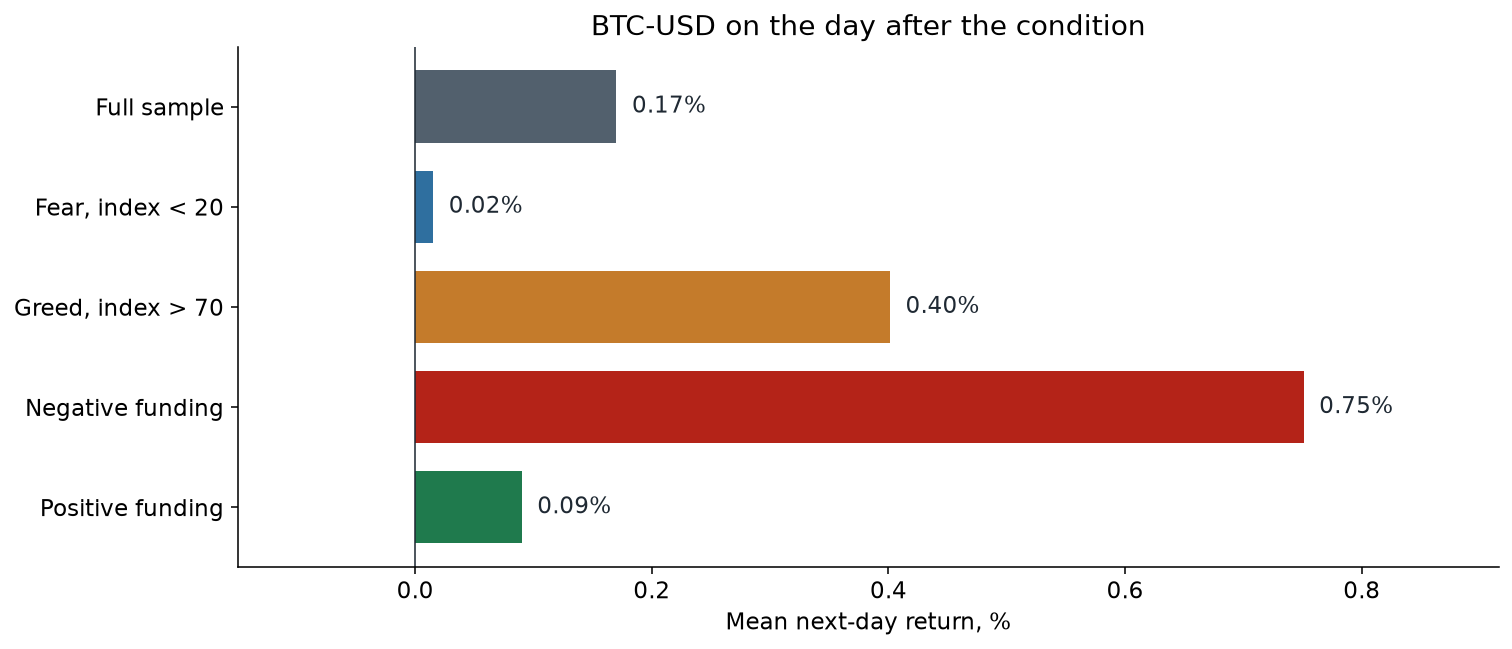

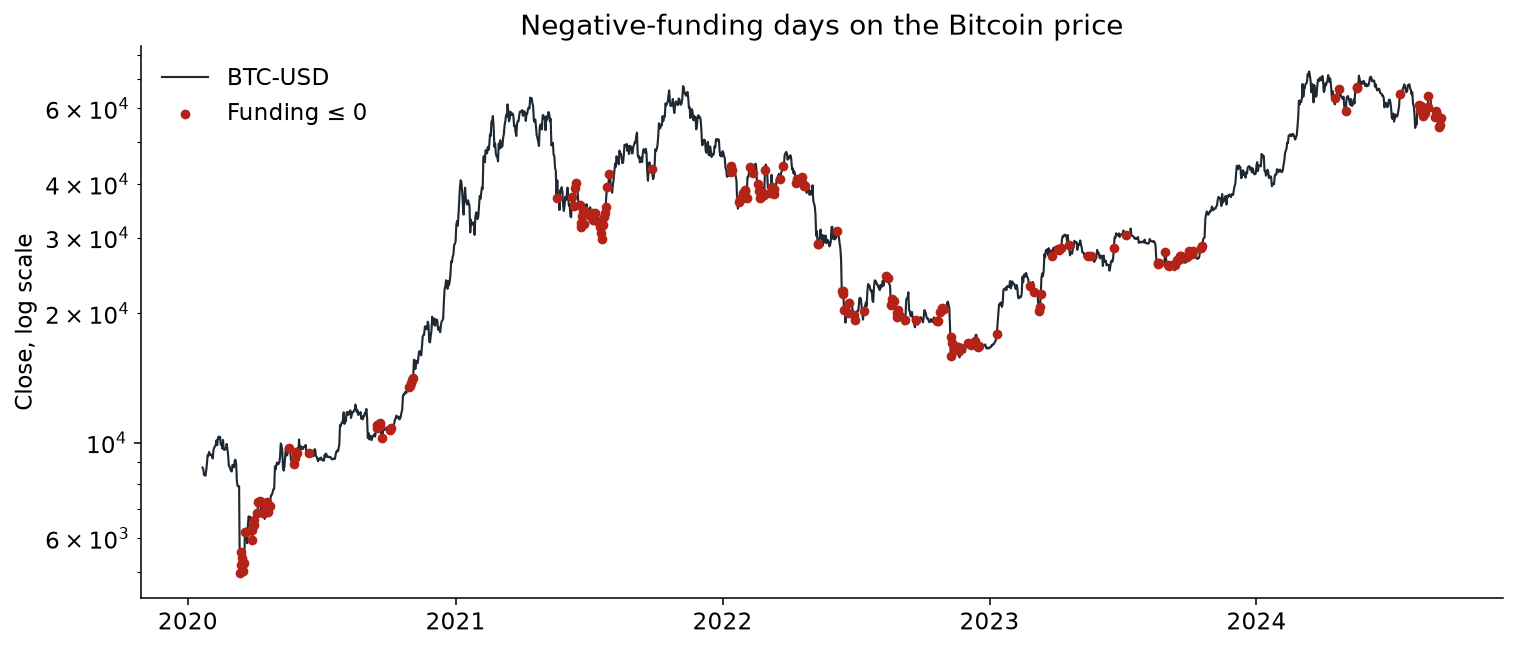

In [5]:
means = [("Full sample", sample["next_day_return"].mean(), "#52606d")]
means.extend(
    (
        name,
        sample.loc[mask, "next_day_return"].mean(),
        color,
    )
    for (name, mask), color in zip(
        CONDITIONS,
        ["#2f6f9f", "#c47b2b", "#b42318", "#1f7a4d"],
    )
)

def show_figure(figure: plt.Figure) -> None:
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


figure, axis = plt.subplots()
labels = [item[0] for item in means]
values = [item[1] * 100 for item in means]
colors = [item[2] for item in means]
positions = np.arange(len(labels))
bars = axis.barh(positions, values, color=colors, height=0.72)
axis.axvline(0, color="#1f2933", lw=0.8)
axis.set_yticks(positions, labels)
axis.set_xlabel("Mean next-day return, %")
axis.set_title("BTC-USD on the day after the condition")
axis.invert_yaxis()
span = max(values) - min(0, min(values))
pad = max(0.12, span * 0.22)
for bar, value in zip(bars, values):
    axis.text(
        value + pad * 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        ha="left",
        color="#1f2933",
    )
axis.set_xlim(min(0, min(values) - pad), max(values) + pad)
figure.tight_layout()
show_figure(figure)

figure, axis = plt.subplots()
axis.plot(sample["date"], sample["close"], color="#1f2933", lw=1.1, label="BTC-USD")
negative = sample[sample["negative_funding"]]
axis.scatter(
    negative["date"],
    negative["close"],
    s=16,
    color="#b42318",
    zorder=3,
    label="Funding ≤ 0",
)
axis.set_yscale("log")
axis.set_ylabel("Close, log scale")
axis.set_title("Negative-funding days on the Bitcoin price")
axis.legend(frameon=False, loc="upper left")
figure.tight_layout()
show_figure(figure)


## Post text

The numbers below are rounded the way the screenshot rounded them. A t-statistic of 1 or more is shown with one decimal place, and a smaller one with two. A p-value below 0.05 is cut to three digits: 0.0358 was written as 0.035.

The greed p-value in the table is about 0.227. Ordinary rounding to two digits gives 0.23. The screenshot says 0.22, and the post text for the original window keeps 0.22.

"8 times" is the ratio of the already rounded percentages 0.75 and 0.09.


In [6]:
def post_t(value: float) -> str:
    if abs(value) >= 1:
        return f"{value:.1f}"
    return f"{value:.2f}"


def post_p(value: float) -> str:
    if value < 0.05:
        # The post wrote 0.0358 as 0.035: it kept three digits and dropped the rest.
        truncated = int(value * 1000) / 1000
        return f"{truncated:.3f}"
    return f"{value:.2f}"


def percent_label(mean: float) -> str:
    return f"{mean * 100:.2f}%"


by_name = {row["condition"]: row for row in published.to_dict("records")}
fear = by_name[f"Fear, index < {FEAR_BELOW}"]
greed = by_name[f"Greed, index > {GREED_ABOVE}"]
negative = by_name["Negative funding"]
positive = by_name["Positive funding"]


def fear_verdict(result: dict) -> str:
    if result["p"] >= 0.05:
        return "Price behaves as usual. Sorry, Buffett!"
    if result["t"] > 0:
        return "Fear days are followed by a larger next-day rise than the sample average."
    return "Fear days are followed by a weaker next-day return than the sample average."


def greed_verdict(result: dict) -> str:
    if result["p"] >= 0.05:
        return "No magic here either. Just normal price behavior."
    if result["t"] > 0:
        return "Greed days are followed by a larger next-day rise than the sample average."
    return "Greed days are followed by a weaker next-day return than the sample average."


def funding_verdict(result: dict) -> str:
    if result["p"] < 0.05 and result["t"] > 0:
        return "BINGO! Statistically significant daily price change increase!"
    if result["p"] < 0.05:
        return "Statistically significant, but the next-day return is lower than the sample average."
    return "No statistically significant difference from the sample average."


negative_pct = round(negative["mean next-day return"] * 100, 2)
positive_pct = round(positive["mean next-day return"] * 100, 2)
if positive_pct > 0 and negative_pct > 0:
    times = round(negative_pct / positive_pct)
    insight = (
        f"Key Insight: With negative funding, price daily rises on average by "
        f"{negative_pct:.2f}%, which is {times} times more than with positive funding "
        f"({positive_pct:.2f}%)!"
    )
else:
    times = None
    insight = (
        "Key Insight: Average next-day return is "
        f"{percent_label(negative['mean next-day return'])} after negative funding "
        f"and {percent_label(positive['mean next-day return'])} after positive funding."
    )

published_window = (
    str(START) == "2020-01-21"
    and str(POST_END) == "2024-09-09"
    and FEAR_BELOW == 20
    and GREED_ABOVE == 70
)
# The screenshot writes the greed p-value as 0.22. The raw value is about 0.227;
# ordinary rounding to two digits gives 0.23. The post text for the original window
# keeps the screenshot figure. The exact p-value is in the table above.
greed_p_text = "0.22" if published_window else post_p(greed["p"])

bingo = negative["p"] < 0.05 and negative["t"] > 0
spoiler = (
    "(Spoiler: negative funding is our bro!)"
    if bingo
    else "(Spoiler: the old slogan does not survive this window.)"
)
conclusion = (
    "Conclusion: Hamsters, prepare to be sheared! Negative funding is our "
    "true friend in the crypto trading world."
    if bingo
    else "Conclusion: On this window the negative-funding slogan from the old post does not hold."
)

start_label = sample["date"].min().date().isoformat()
end_label = sample["date"].max().date().isoformat()
post = f'''FEAR & GREED INDEX vs FUNDING RATE: BATTLE OF THE TITANS!

"Be fearful when others are greedy and greedy when others are fearful" - Warren Buffett
"Mass shorts = liquidation of hamsters" - Crypto traders

Let's test these claims with t-tests from math stats!
{spoiler}

Extreme Fear (index < {FEAR_BELOW}):
T-stats: {post_t(fear["t"])}, P-value: {post_p(fear["p"])}
Verdict: {fear_verdict(fear)}

Extreme Greed (index > {GREED_ABOVE}):
T-stats: {post_t(greed["t"])}, P-value: {greed_p_text}
Verdict: {greed_verdict(greed)}

Negative Funding (funding rate < 0):
T-stats: {post_t(negative["t"])}, P-value: {post_p(negative["p"])}
Verdict: {funding_verdict(negative)}

{insight}

{conclusion}

#Cryptocurrencies #Bitcoin #TradingStrategies #DataScience #Trading #fintech #cryptoinvesting #crypto #investingtips #cryptotip

P.S. Data {start_label} to {end_label}. Funding from Binance BTCUSDT perpetual (last print of each UTC day), fear and greed index from alternative.me. Each t-test compares next-day BTC-USD returns on the selected days with the average next-day return of the whole sample. Not investment advice, DYOR!
'''
print(post)

expected = {
    "fear": ("-0.32", "0.75"),
    "greed": ("1.2", "0.22"),
    "funding": ("2.1", "0.035"),
    "negative_return": "0.75%",
    "positive_return": "0.09%",
    "times": 8,
}
actual = {
    "fear": (post_t(fear["t"]), post_p(fear["p"])),
    "greed": (post_t(greed["t"]), greed_p_text),
    "funding": (post_t(negative["t"]), post_p(negative["p"])),
    "negative_return": f"{negative_pct:.2f}%",
    "positive_return": f"{positive_pct:.2f}%",
    "times": times,
}
if published_window:
    mismatches = {key: (actual[key], expected[key]) for key in expected if actual[key] != expected[key]}
    if mismatches:
        print("Post check failed:", mismatches)
    else:
        print("Post check: every rounded figure matches.")
    print(
        f"Greed p-value in the table: {greed['p']:.4f}. "
        "The screenshot writes 0.22; rounding to two digits gives 0.23."
    )
else:
    print("Window or thresholds changed, so the September 2024 post check was skipped.")


FEAR & GREED INDEX vs FUNDING RATE: BATTLE OF THE TITANS!

"Be fearful when others are greedy and greedy when others are fearful" - Warren Buffett
"Mass shorts = liquidation of hamsters" - Crypto traders

Let's test these claims with t-tests from math stats!
(Spoiler: negative funding is our bro!)

Extreme Fear (index < 20):
T-stats: -0.32, P-value: 0.75
Verdict: Price behaves as usual. Sorry, Buffett!

Extreme Greed (index > 70):
T-stats: 1.2, P-value: 0.22
Verdict: No magic here either. Just normal price behavior.

Negative Funding (funding rate < 0):
T-stats: 2.1, P-value: 0.035
Verdict: BINGO! Statistically significant daily price change increase!

Key Insight: With negative funding, price daily rises on average by 0.75%, which is 8 times more than with positive funding (0.09%)!

Conclusion: Hamsters, prepare to be sheared! Negative funding is our true friend in the crypto trading world.

#Cryptocurrencies #Bitcoin #TradingStrategies #DataScience #Trading #fintech #cryptoinvesting 

## Funding on newer data

The three windows use one rule. Next-day return is the next BTC-USD close, taken from the full price series rather than cut off at the window boundary. A day with no following close is left out of the table.

- Original window: 21 January 2020 through 9 September 2024. These are the post dates, but 9 September here already has a next-day return. The mean therefore differs slightly from the 0.75% in the post text.
- New stretch: from the next day, 10 September 2024, through the last day that has funding and a following close.
- Full history: both pieces together, with no gap and no double-counting of the boundary.

The main test is Welch's t-test of days with funding less than or equal to zero against the other days in the same window. Beside it is the post's version: the group against the whole window, including itself.


,window,from,to,days,days with funding < 0,"mean, all days",mean after funding < 0,mean after funding > 0,median after funding < 0,median after funding > 0,up-day share after < 0,up-day share on other days,t versus other days,p versus other days,t versus full sample,p versus full sample
0,Original window,2020-01-21,2024-09-09,1694,206,0.17%,0.75%,0.09%,0.24%,0.01%,56.31%,50.20%,2.40,0.0170,2.12,0.0351
1,New stretch,2024-09-10,2026-09-30,751,119,0.08%,0.29%,0.04%,0.10%,-0.03%,54.62%,49.21%,1.01,0.3157,0.85,0.3948
2,Full history,2020-01-21,2026-09-30,2445,325,0.14%,0.58%,0.07%,0.20%,-0.00%,55.69%,49.91%,2.56,0.0108,2.23,0.0260


Original window: mean after funding < 0 is 0.75%, on other days 0.09%. the mean is higher than on other days, and the difference clears 5%. t = 2.40, p = 0.017.
New stretch: mean after funding < 0 is 0.29%, on other days 0.04%. the difference from other days does not clear 5%. t = 1.01, p = 0.316.
Full history: mean after funding < 0 is 0.58%, on other days 0.07%. the mean is higher than on other days, and the difference clears 5%. t = 2.56, p = 0.011.


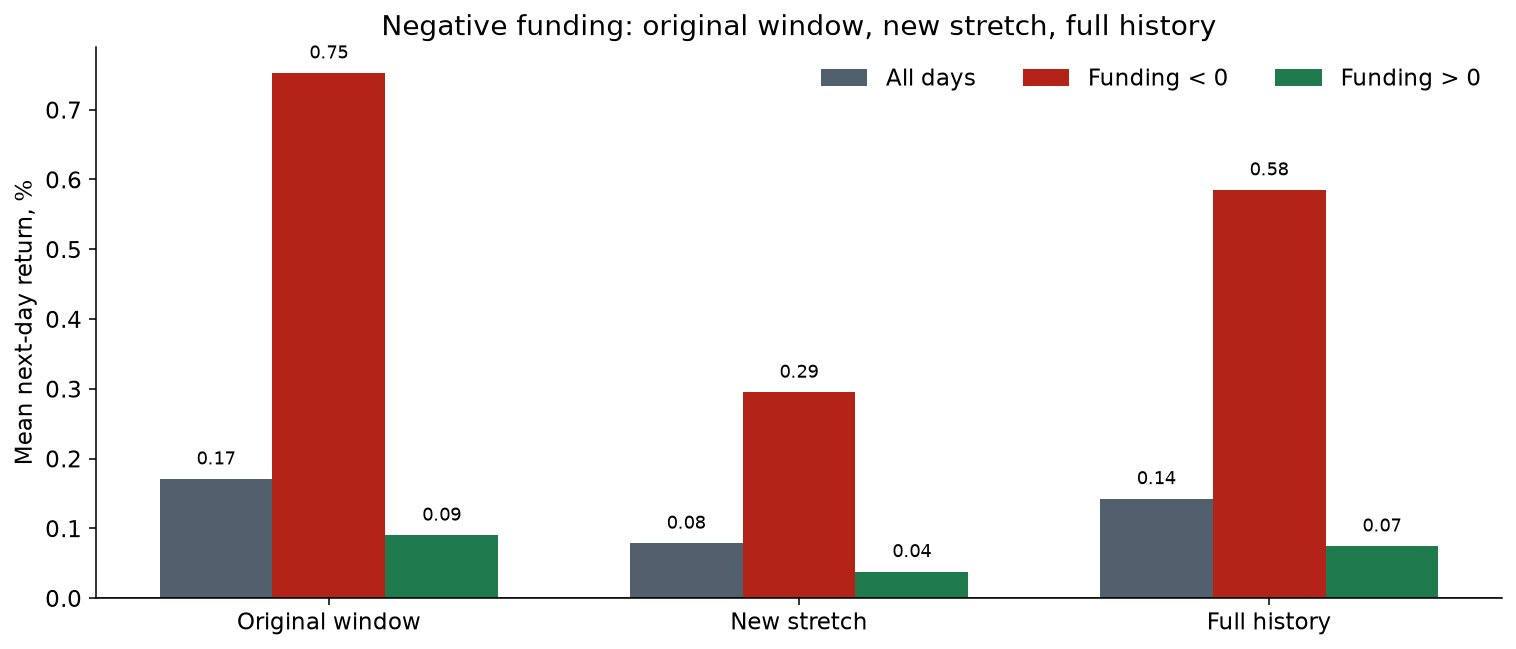

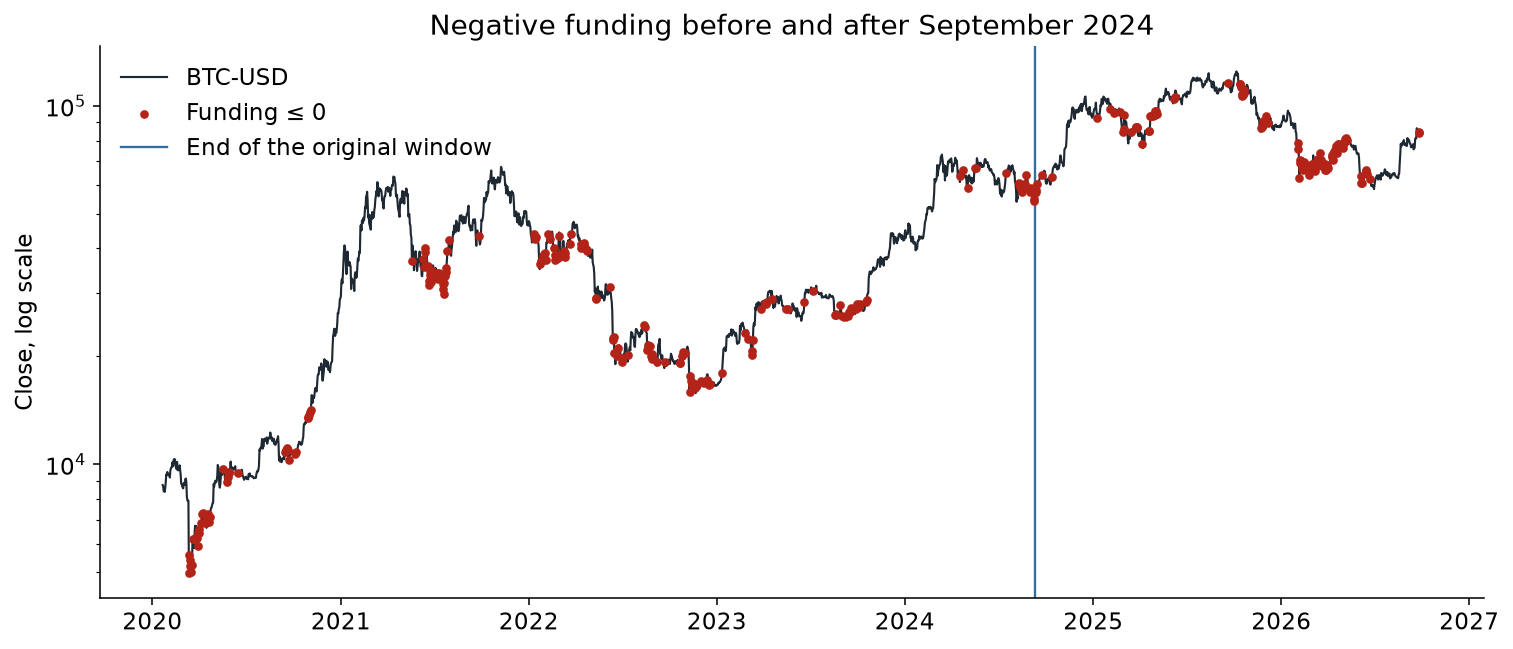

In [7]:
def funding_window(name: str, frame: pd.DataFrame) -> dict:
    negative = frame["negative_funding"]
    group = frame.loc[negative, "forward_return"]
    rest = frame.loc[~negative, "forward_return"]
    t_rest, p_rest = welch(group, int(negative.sum()), rest, int((~negative).sum()))
    t_all, p_all = welch(group, int(negative.sum()), frame["forward_return"], len(frame))
    return {
        "window": name,
        "from": frame["date"].min().date().isoformat(),
        "to": frame["date"].max().date().isoformat(),
        "days": len(frame),
        "days with funding < 0": int(negative.sum()),
        "mean, all days": frame["forward_return"].mean(),
        "mean after funding < 0": group.mean(),
        "mean after funding > 0": rest.mean(),
        "median after funding < 0": group.median(),
        "median after funding > 0": rest.median(),
        "up-day share after < 0": float((group > 0).mean()),
        "up-day share on other days": float((rest > 0).mean()),
        "t versus other days": t_rest,
        "p versus other days": p_rest,
        "t versus full sample": t_all,
        "p versus full sample": p_all,
    }


old_window = history[history["date"] <= post_end]
new_window = history[history["date"] > post_end]
windows = pd.DataFrame(
    [
        funding_window("Original window", old_window),
        funding_window("New stretch", new_window),
        funding_window("Full history", history),
    ]
)

view = windows.copy()
percent_columns = [
    "mean, all days",
    "mean after funding < 0",
    "mean after funding > 0",
    "median after funding < 0",
    "median after funding > 0",
    "up-day share after < 0",
    "up-day share on other days",
]
for column in percent_columns:
    view[column] = windows[column].map(lambda value: f"{value:.2%}")
for column in ("t versus other days", "t versus full sample"):
    view[column] = windows[column].map(lambda value: f"{value:.2f}")
for column in ("p versus other days", "p versus full sample"):
    view[column] = windows[column].map(lambda value: f"{value:.4f}")
display(view)

for row in windows.to_dict("records"):
    if row["p versus other days"] < 0.05 and row["t versus other days"] > 0:
        verdict = "the mean is higher than on other days, and the difference clears 5%"
    elif row["p versus other days"] < 0.05:
        verdict = "the difference from other days clears 5%, and the mean is lower"
    else:
        verdict = "the difference from other days does not clear 5%"
    print(
        f"{row['window']}: mean after funding < 0 is {row['mean after funding < 0']:.2%}, "
        f"on other days {row['mean after funding > 0']:.2%}. {verdict}. "
        f"t = {row['t versus other days']:.2f}, p = {row['p versus other days']:.3f}."
    )

labels = windows["window"].tolist()
series = [
    ("All days", "mean, all days", "#52606d"),
    ("Funding < 0", "mean after funding < 0", "#b42318"),
    ("Funding > 0", "mean after funding > 0", "#1f7a4d"),
]
positions = np.arange(len(labels))
width = 0.24
figure, axis = plt.subplots()
for index, (name, column, color) in enumerate(series):
    values = windows[column].to_numpy() * 100
    bars = axis.bar(positions + (index - 1) * width, values, width, label=name, color=color)
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )
axis.set_xticks(positions, labels)
axis.set_ylabel("Mean next-day return, %")
axis.set_title("Negative funding: original window, new stretch, full history")
axis.axhline(0, color="#1f2933", lw=0.8)
axis.legend(frameon=False, ncol=3, loc="upper right")
figure.tight_layout()
show_figure(figure)

figure, axis = plt.subplots()
axis.plot(history["date"], history["close"], color="#1f2933", lw=1.1, label="BTC-USD")
negative = history[history["negative_funding"]]
axis.scatter(
    negative["date"],
    negative["close"],
    s=12,
    color="#b42318",
    zorder=3,
    label="Funding ≤ 0",
)
axis.axvline(post_end, color="#2f6f9f", lw=1.2, label="End of the original window")
axis.set_yscale("log")
axis.set_ylabel("Close, log scale")
axis.set_title("Negative funding before and after September 2024")
axis.legend(frameon=False, loc="upper left")
figure.tight_layout()
show_figure(figure)


## What to change next

- A later end of the history shows up on its own: set `END = None` and run the notebook again after Binance publishes the next monthly funding file. The current month usually appears in the archive after the month closes.
- A different greed threshold in the post text: change `GREED_ABOVE`. The value 80 is the screenshot caption, not the threshold that produced 1.2 and 0.22.
- The second table in the t-test section compares the group with the other days inside the post window. The post text reads the first table.
